In [45]:
import numpy as np
import pandas as pd
data = pd.read_csv('insurance.csv')
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Data Processing

In [46]:
data.shape

(1338, 7)

In [47]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [48]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [49]:
#value counts for categorical variables
print(data.sex.value_counts(),'\n',data.smoker.value_counts(),'\n',data.region.value_counts())

sex
male      676
female    662
Name: count, dtype: int64 
 smoker
no     1064
yes     274
Name: count, dtype: int64 
 region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


In [50]:
#changing categorical variables to numerical
data['sex'] = data['sex'].map({'male':1,'female':0})
data['smoker'] = data['smoker'].map({'yes':1,'no':0})
data['region'] = data['region'].map({'southwest':0,'southeast':1,'northwest':2,'northeast':3})

In [51]:
data.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,0,16884.92400
1,18,1,33.770,1,0,1,1725.55230
2,28,1,33.000,3,0,1,4449.46200
3,33,1,22.705,0,0,2,21984.47061
4,32,1,28.880,0,0,2,3866.85520
5,31,0,25.740,0,0,1,3756.62160
6,46,0,33.440,1,0,1,8240.58960
7,37,0,27.740,3,0,2,7281.50560
8,37,1,29.830,2,0,3,6406.41070
9,60,0,25.840,0,0,2,28923.13692


# Exploratory Data Analysis

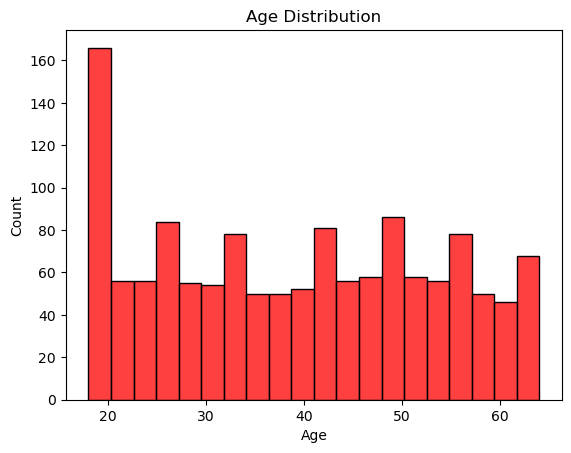

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
#age distribution
sns.histplot(data.age,bins=20,color='red')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

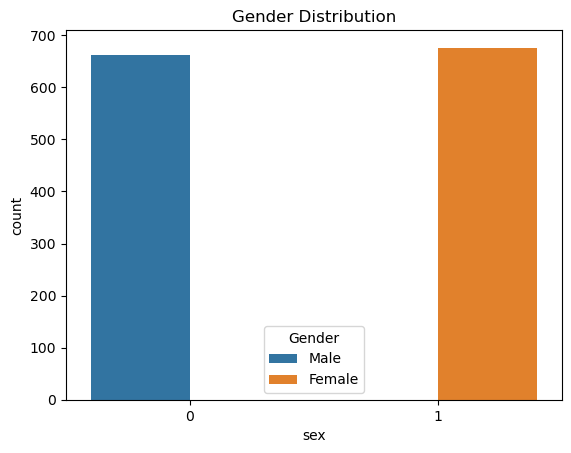

In [9]:
sns.countplot(x='sex', data=data, hue='sex')
plt.legend(title='Gender', labels=['Male', 'Female'])
plt.title('Gender Distribution')
plt.show()


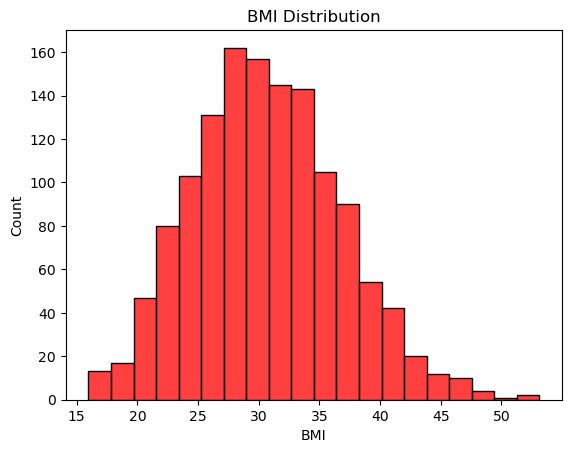

In [10]:
#bmi distribution
sns.histplot(data.bmi,bins=20,color='red')
plt.title('BMI Distribution')
plt.xlabel('BMI')
plt.ylabel('Count')
plt.show()

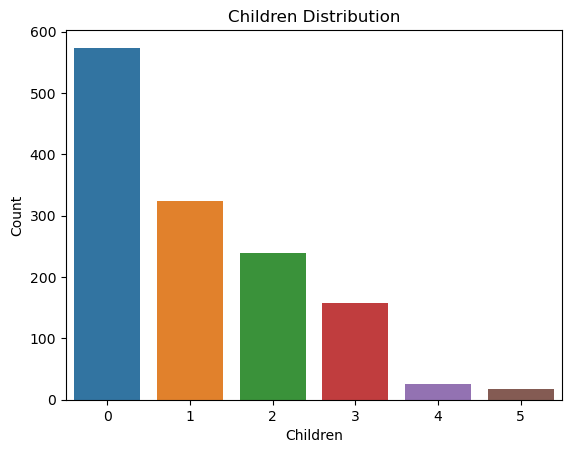

In [11]:
#child count distribution
sns.countplot(x = 'children', data = data)
plt.title('Children Distribution')
plt.xlabel('Children')
plt.ylabel('Count')
plt.show()

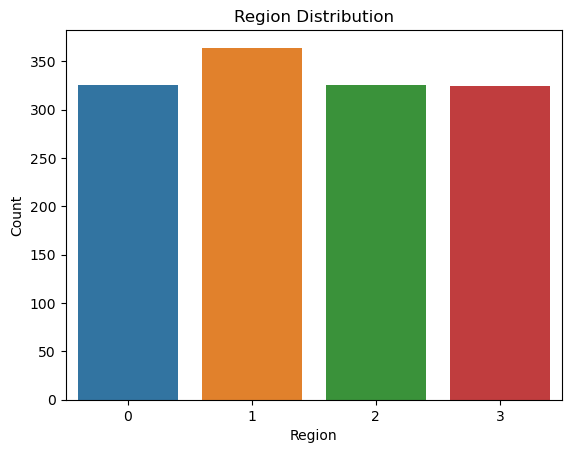

In [12]:
#regionwise plot
sns.countplot(x = 'region', data = data)
plt.title('Region Distribution')
plt.xlabel('Region')
plt.ylabel('Count')
plt.show()

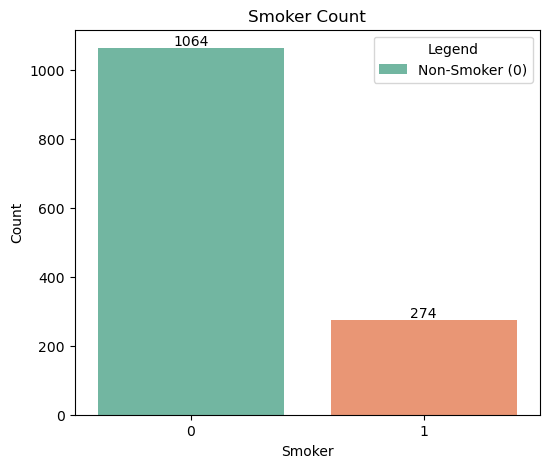

In [13]:
plt.figure(figsize=(6, 5))
sns.countplot(x='smoker', data=data, palette='Set2')

plt.title('Smoker Count')
plt.xlabel('Smoker')
plt.ylabel('Count')

# Adding labels to the bars
for i, count in enumerate(data['smoker'].value_counts()):
    plt.text(i, count + 0.1, str(count), ha='center', va='bottom')

# Adding legend
plt.legend(title='Legend', labels=['Non-Smoker (0)', 'Smoker (1)'])

plt.show()


<Axes: xlabel='smoker', ylabel='count'>

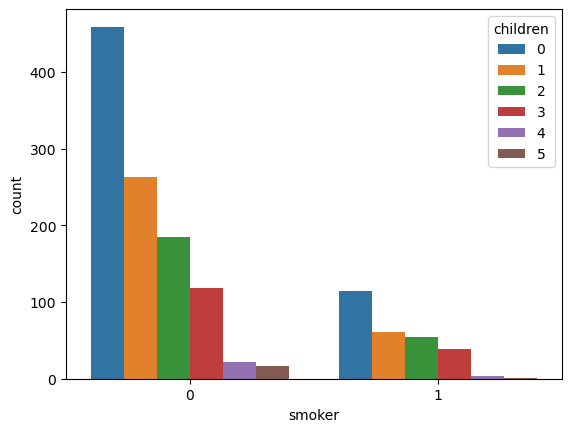

In [14]:
sns.countplot(x = data.smoker, hue = data.children)

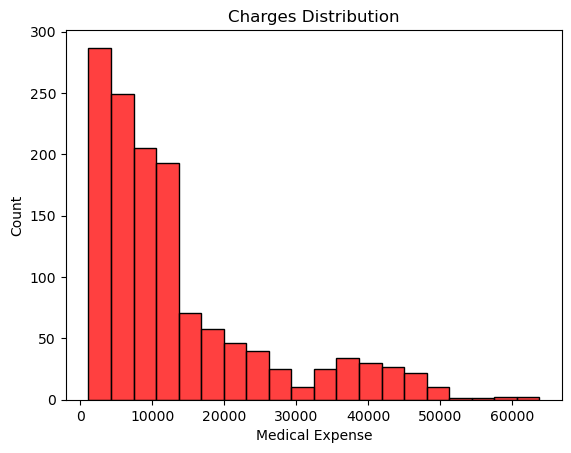

In [15]:
#charges distribution
sns.histplot(data.charges,bins=20,color='red')
plt.title('Charges Distribution')
plt.xlabel('Medical Expense')
plt.ylabel('Count')
plt.show()

# Coorelation

In [16]:
data.corr()

,age,sex,bmi,children,smoker,region,charges
age,1.000000,-0.020856,0.109272,0.042469,-0.025019,-0.002127,0.299008
sex,-0.020856,1.000000,0.046371,0.017163,0.076185,-0.004588,0.057292
bmi,0.109272,0.046371,1.000000,0.012759,0.003750,-0.157566,0.198341
children,0.042469,0.017163,0.012759,1.000000,0.007673,-0.016569,0.067998
smoker,-0.025019,0.076185,0.003750,0.007673,1.000000,0.002181,0.787251
region,-0.002127,-0.004588,-0.157566,-0.016569,0.002181,1.000000,0.006208
charges,0.299008,0.057292,0.198341,0.067998,0.787251,0.006208,1.000000


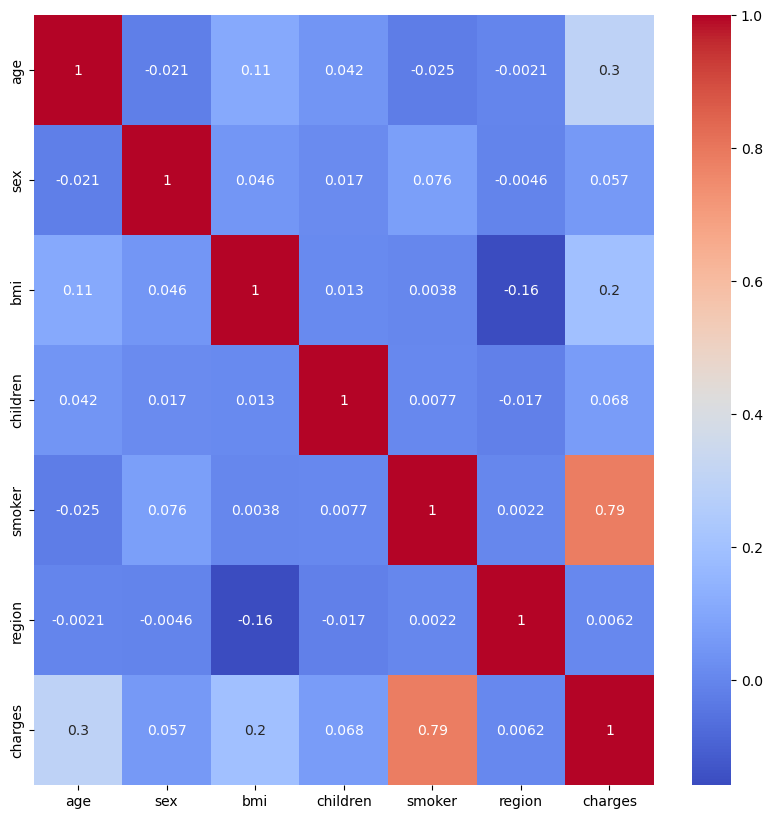

In [17]:
plt.figure(figsize=(10,10))
sns.heatmap(data.corr(),annot=True,cmap='coolwarm')
plt.show()

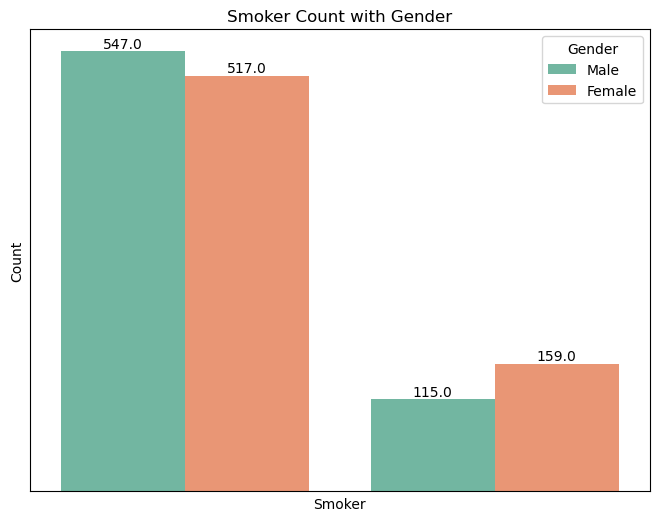

In [18]:
import warnings
# Filter the warning
warnings.filterwarnings("ignore", message="The figure layout has changed to tight")

# Plotting the smoker count with patient's gender
plt.figure(figsize=(8, 6))
ax = sns.countplot(x="smoker", hue='sex', data=data, palette='Set2')

plt.title('Smoker Count with Gender')
plt.xlabel('Smoker')
plt.ylabel('Count')

plt.tick_params(axis='both', which='both', left=False, bottom=False, labelleft=False, labelbottom=False)

# Adding legend with adjusted positioning
plt.legend(title='Gender', labels=['Male', 'Female'], loc='upper right')

# Adding text annotations for smokers and non-smokers
for p in ax.patches:
    ax.annotate(f"{p.get_height()}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.1),
                ha='center', va='bottom')

plt.show()


<Axes: title={'center': 'Box plot for charges of women'}, xlabel='charges', ylabel='smoker'>

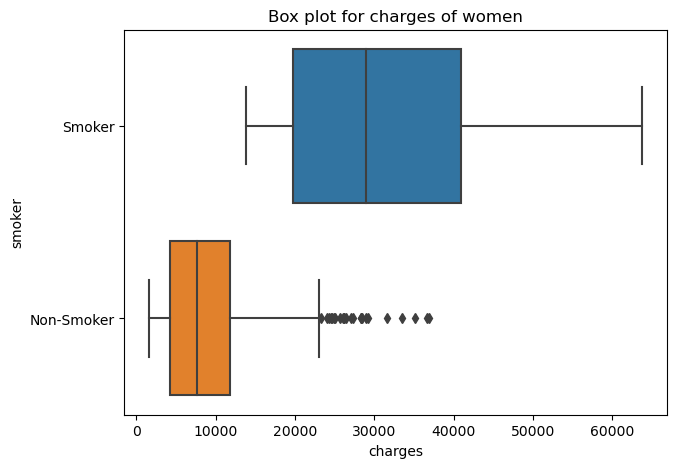

In [19]:
plt.figure(figsize=(7,5))
plt.title("Box plot for charges of women")
sns.boxplot(y="smoker", x="charges", data=data[data.sex == 0].replace({'smoker': {0: 'Non-Smoker', 1: 'Smoker'}}), orient="h")


<Axes: title={'center': 'Box plot for charges of men'}, xlabel='charges', ylabel='smoker'>

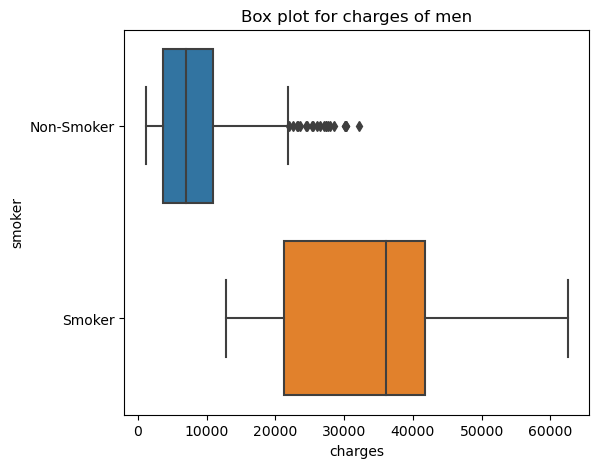

In [20]:
plt.figure(figsize=(6, 5))
plt.title("Box plot for charges of men")
sns.boxplot(y="smoker", x="charges", data=data[data.sex == 1].replace({'smoker': {0: 'Non-Smoker', 1: 'Smoker'}}), orient="h")


# Smoke and Age Distribution

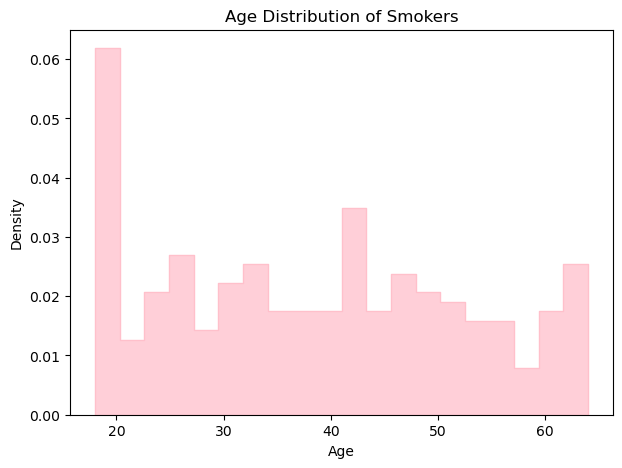

In [21]:
smokers_data = data[data['smoker'] == 1]

plt.figure(figsize=(7, 5))
sns.histplot(x="age", data=smokers_data, bins=20, element="step", stat="density", common_norm=False, color='pink')

plt.title("Age Distribution of Smokers")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()


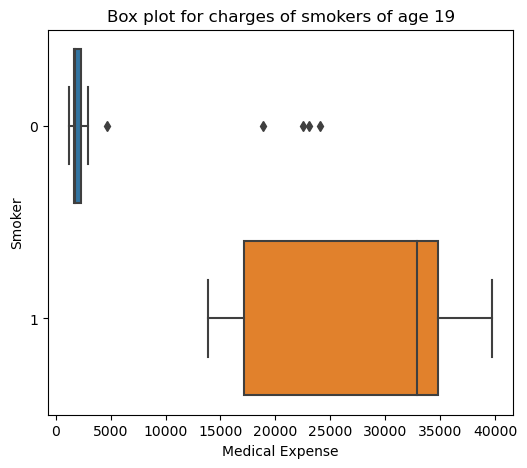

In [22]:
#smokers of age 19
plt.figure(figsize=(6,5))
plt.title("Box plot for charges of smokers of age 19")
sns.boxplot(y="smoker", x="charges", data =  data[(data.age == 19)] , orient="h")
plt.xlabel('Medical Expense')
plt.ylabel('Smoker')
plt.show()

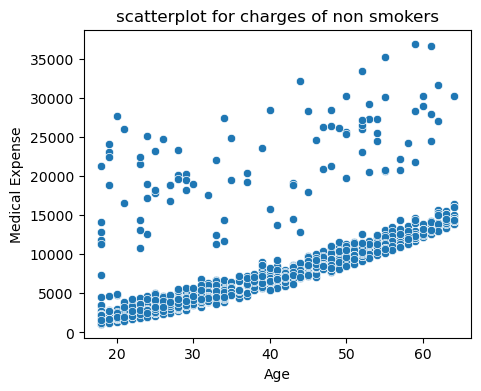

In [23]:
#non smokers charge distribution
plt.figure(figsize=(5,4))
plt.title("scatterplot for charges of non smokers")
sns.scatterplot(x="age", y="charges", data =  data[(data.smoker == 0)])
plt.xlabel('Age')
plt.ylabel('Medical Expense')
plt.show()

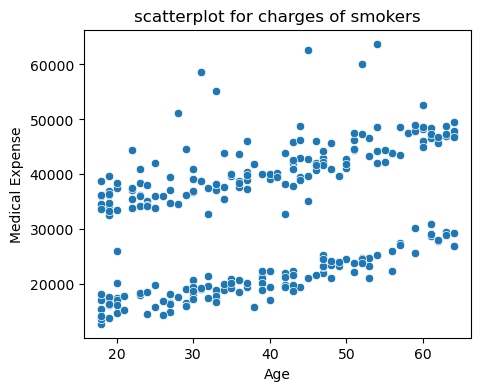

In [24]:
#smokers charge distribution
plt.figure(figsize=(5,4))
plt.title("scatterplot for charges of smokers")
sns.scatterplot(x="age", y="charges", data =  data[(data.smoker == 1)])
plt.xlabel('Age')
plt.ylabel('Medical Expense')
plt.show()

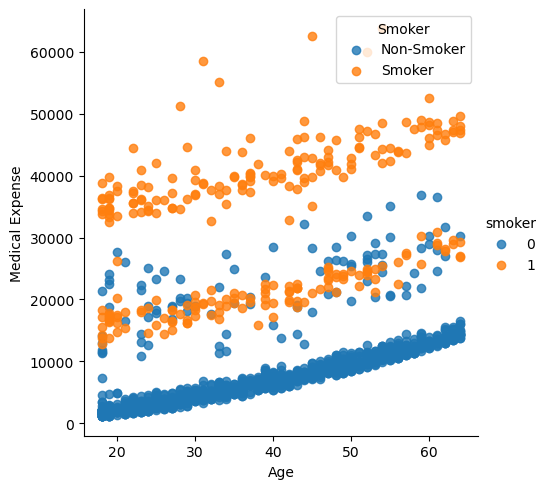

In [25]:
legend_labels = {0: 'Non-Smoker', 1: 'Smoker'}
sns.lmplot(x="age", y="charges", data=data, hue='smoker', fit_reg=False)
plt.legend(title='Smoker', labels=legend_labels.values())
plt.xlabel('Age')
plt.ylabel('Medical Expense')
plt.show()


Charges distribution for patients with BMI greater than 30 i.e. obese patients

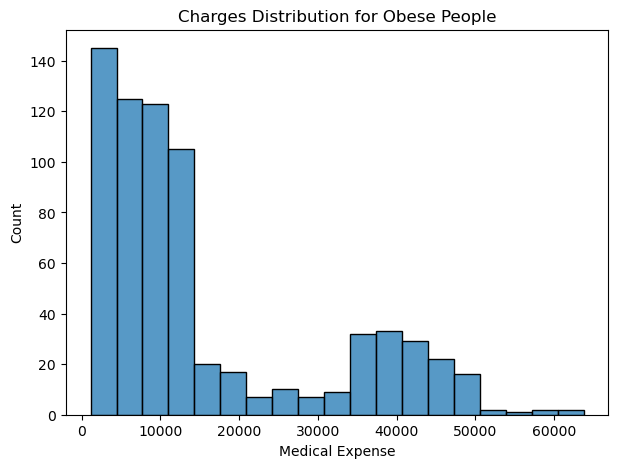

In [26]:
plt.figure(figsize=(7, 5))
sns.histplot(data=data[data.bmi >= 30], x='charges')
plt.title('Charges Distribution for Obese People')
plt.xlabel('Medical Expense')
plt.show()


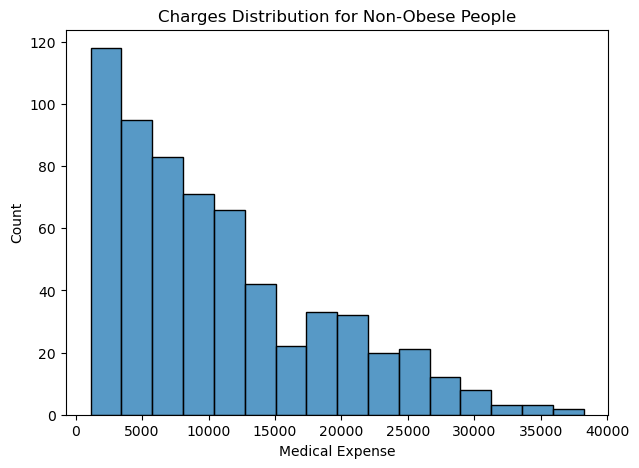

In [27]:
#Charges distribution for patients with BMI less than 30 i.e. healthy patients
plt.figure(figsize=(7, 5))
sns.histplot(data=data[data.bmi < 30], x='charges')
plt.title('Charges Distribution for Non-Obese People')
plt.xlabel('Medical Expense')
plt.show()


# Train Test Split

In [29]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(data.drop('charges',axis=1), data['charges'], test_size=0.2, random_state=0)

In [30]:
print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1070, 6)
X_test shape: (268, 6)
y_train shape: (1070,)
y_test shape: (268,)


# Model Building

# Linear Regression

In [31]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr

LinearRegression()

In [33]:
#model training
lr.fit(x_train,y_train)
lr.score(x_train,y_train)

0.7368306228430945

In [34]:
#model prediction
y_pred = lr.predict(x_test)

In [35]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

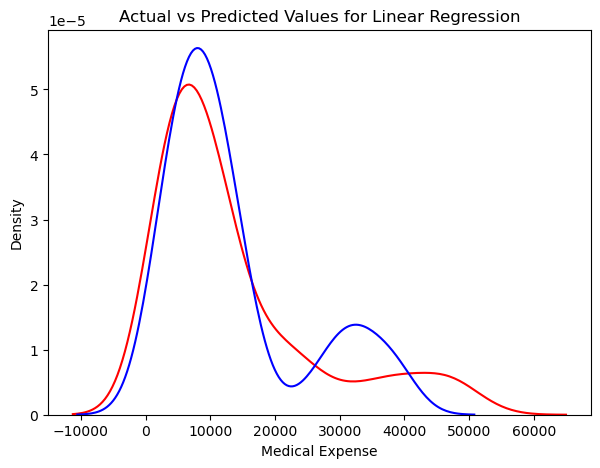

In [37]:
plt.figure(figsize=(7, 5))
ax1 = sns.kdeplot(y_test, color='r', label='Actual Value', fill=False)
sns.kdeplot(y_pred, color='b', label='Predicted Value', fill=False, ax=ax1)
plt.title('Actual vs Predicted Values for Linear Regression')
plt.xlabel('Medical Expense')
plt.show()


In [38]:
print('MAE:', mean_absolute_error(y_test, y_pred))
print('MSE:', mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2 Score:', r2_score(y_test, y_pred))

MAE: 3930.333273901143
MSE: 31845929.134159442
RMSE: 5643.219748880903
R2 Score: 0.7998747145449958


# Decision Tree Regressor

In [39]:
from sklearn.tree import DecisionTreeRegressor
dtree = DecisionTreeRegressor()
dtree

DecisionTreeRegressor()

In [40]:
#model training
dtree.fit(x_train,y_train)
dtree.score(x_train,y_train)

0.9982963931606104

In [41]:
#model prediction
dtree_pred = dtree.predict(x_test)

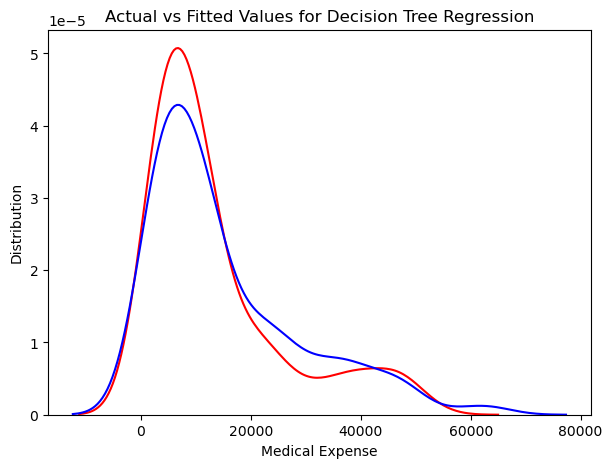

In [43]:
plt.figure(figsize=(7, 5))
ax = sns.kdeplot(y_test, color="r", label="Actual Value", fill=False)
sns.kdeplot(dtree_pred, color="b", label="Fitted Values", fill=False, ax=ax)
plt.title('Actual vs Fitted Values for Decision Tree Regression')
plt.xlabel('Medical Expense')
plt.ylabel('Distribution')
plt.show()


In [44]:
print('MAE:', mean_absolute_error(y_test, dtree_pred))
print('MSE:', mean_squared_error(y_test, dtree_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, dtree_pred)))
print('Accuracy:', dtree.score(x_test,y_test))

MAE: 3762.992976115672
MSE: 57105298.60765597
RMSE: 7556.804788245888
Accuracy: 0.6411405006678872
